# Braun et al. (2026), Supp. Fig. 6 — fitting a Gaussian bump to experimental sequences (WP0.7, WP2.3 input)

> A–C (mouse MEC): mean of 24 sequences rescaled to 177.8 s, centred, rescaled to 8.5 s, averaged, fitted:
> a = 0.29, σ = 1.68 s, b = 0.15, R² = 0.99. D–F (bat CA1): time-cell sequence (168 cells, 6 s), centred, fitted:
> a = 0.83, σ = 1.72 s, b = 0.05, R² = 0.99.

**Data.** Bat: the public Zenodo deposit of Omer, Las & Ulanovsky (2023) (doi:10.5281/zenodo.7213099, CC BY 4.0),
`Fig_2.mat → panel_a.correct`: **166** observer-bat time cells, z-scored rates, 0.1-s bins from landing. Braun used
168 cells averaged over all hanging intervals; this is the closest public proxy (deviation recorded in REPORT.md).
Mouse: blocked on [DATA] (`configs/wp0/data.yaml: mec.path`); the cells below run unchanged once the path is set.

**Panels:** D bat sequence (preprocessed target) · E centred sequence · F bump and fit · A–C mouse (skeleton).
Pipelines: `seqnet.data.bat`, `seqnet.data.mec`, `seqnet.data.common` (spec 6.18).

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet.sequences.datasets import bat, mec
from seqnet.experiments.runner import repo_root

style()
fig = Figure("wp0", "braun_supp6")
dcfg = wp0.data_config()

## Panel D — bat time-cell sequence after Braun's preprocessing (6 s, 0.129-s bins, normalized)

In [2]:
z = bat.load_zscored(repo_root() / dcfg["bat"]["path"], dcfg["bat"]["field"])
tg = bat.preprocess(z)
fig.save("D_bat_sequence", params=dcfg["bat"], rates=tg.rates, z=tg.z_window, bin_size=tg.bin_size, n_cells_loaded=z.shape[0])

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp6/D_bat_sequence.npz')

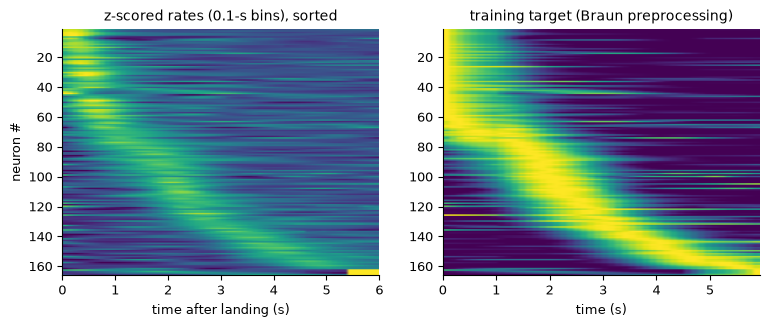

In [3]:
d = fig.load("D_bat_sequence")
F, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].imshow(d["z"], aspect="auto", extent=[0, 6, d["z"].shape[0], 1], vmin=-2, vmax=4); axs[0].set_title("z-scored rates (0.1-s bins), sorted"); axs[0].set_xlabel("time after landing (s)"); axs[0].set_ylabel("neuron #")
axs[1].imshow(d["rates"], aspect="auto", extent=[0, d["rates"].shape[1] * float(d["bin_size"]), d["rates"].shape[0], 1], vmin=0, vmax=1)
axs[1].set_title("training target (Braun preprocessing)"); axs[1].set_xlabel("time (s)")
fig.savefig("D_bat_sequence", F); plt.show()

## Panels E–F — centred sequence (peak at bin 24), rescaled to 8.5 s, mean across neurons, Gaussian fit

In [4]:
fit, centred = bat.bump_fit(tg)
fig.save("EF_bat_fit", centred=centred, t=fit.t, bump=fit.bump, model=fit.model(fit.t),
         amp=fit.amp, width=fit.width, offset=fit.offset, r2=fit.r2, paper=np.array([0.83, 1.72, 0.05, 0.99]))
(repo_root() / "results" / "wp0" / "data" / "braun_supp6" / "fit_bat.json").write_text(
    json.dumps({"amp": fit.amp, "width": fit.width, "offset": fit.offset, "r2": fit.r2, "n_cells": int(tg.N)}, indent=1))

135

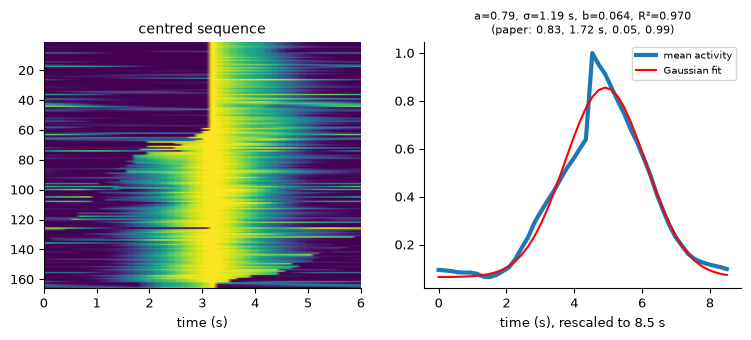

In [5]:
d = fig.load("EF_bat_fit")
F, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].imshow(d["centred"], aspect="auto", extent=[0, 6, d["centred"].shape[0], 1], vmin=0, vmax=1); axs[0].set_title("centred sequence"); axs[0].set_xlabel("time (s)")
axs[1].plot(d["t"], d["bump"], color="tab:blue", lw=3, label="mean activity"); axs[1].plot(d["t"], d["model"], "r", label="Gaussian fit")
axs[1].set_xlabel("time (s), rescaled to 8.5 s"); axs[1].legend(fontsize=7)
axs[1].set_title(f"a={float(d['amp']):.2f}, σ={float(d['width']):.2f} s, b={float(d['offset']):.3f}, R²={float(d['r2']):.3f}\n(paper: 0.83, 1.72 s, 0.05, 0.99)", fontsize=8)
fig.savefig("EF_bat_fit", F); plt.show()

## Panels A–C — mouse MEC (skeleton; runs when `mec.path` is set)

In [6]:
mec_ok = mec.available(None if dcfg["mec"]["path"] is None else repo_root() / dcfg["mec"]["path"])
if mec_ok:
    s = mec.load_session(repo_root() / dcfg["mec"]["path"])
    fit_m, centred_m = mec.bump_fit(s)
    fig.save("ABC_mec_fit", mean_seq=mec.mean_sequence(s), centred=centred_m, t=fit_m.t, bump=fit_m.bump, model=fit_m.model(fit_m.t),
             amp=fit_m.amp, width=fit_m.width, offset=fit_m.offset, r2=fit_m.r2)
    (repo_root() / "results" / "wp0" / "data" / "braun_supp6" / "fit_mec.json").write_text(
        json.dumps({"amp": fit_m.amp, "width": fit_m.width, "offset": fit_m.offset, "r2": fit_m.r2}, indent=1))
else:
    print("MEC data not available (configs/wp0/data.yaml: mec.path = None) -- panels A-C skipped [DATA]")

MEC data not available (configs/wp0/data.yaml: mec.path = None) -- panels A-C skipped [DATA]


In [7]:
if mec_ok:
    d = fig.load("ABC_mec_fit")
    F, axs = plt.subplots(1, 3, figsize=(13, 3.2))
    axs[0].imshow(d["mean_seq"], aspect="auto", vmin=0, vmax=1); axs[0].set_title("mean sequence")
    axs[1].imshow(d["centred"], aspect="auto", vmin=0, vmax=1); axs[1].set_title("centred mean sequence")
    axs[2].plot(d["t"], d["bump"], lw=3); axs[2].plot(d["t"], d["model"], "r"); axs[2].set_title(f"a={float(d['amp']):.2f}, σ={float(d['width']):.2f}, b={float(d['offset']):.2f}")
    fig.savefig("ABC_mec_fit", F); plt.show()

## Acceptance

In [8]:
d = fig.load("EF_bat_fit")
checks = [
    {"item": "bat bump fit vs paper (a = 0.83, sigma = 1.72 s, b = 0.05)", "criterion": "each within factor 1.5 (proxy data: 166 cells, correct trials)",
     "value": {"amp": float(d["amp"]), "width": float(d["width"]), "offset": float(d["offset"]), "r2": float(d["r2"])},
     "passed": bool(0.83 / 1.5 <= d["amp"] <= 0.83 * 1.5 and 1.72 / 1.5 <= d["width"] <= 1.72 * 1.5 and d["offset"] <= 0.075)},
    {"item": "bat fit quality", "criterion": "R^2 >= 0.95 (paper 0.99)", "value": float(d["r2"]), "passed": bool(d["r2"] >= 0.95)},
]
if mec_ok:
    m = fig.load("ABC_mec_fit")
    checks.append({"item": "mouse bump fit vs paper (0.29, 1.68 s, 0.15)", "criterion": "each within factor 1.5",
                   "value": {"amp": float(m["amp"]), "width": float(m["width"]), "offset": float(m["offset"])},
                   "passed": bool(0.29 / 1.5 <= m["amp"] <= 0.435 and 1.12 <= m["width"] <= 2.52 and 0.1 <= m["offset"] <= 0.225)})
else:
    checks.append({"item": "mouse bump fit", "criterion": "blocked [DATA]", "value": None, "passed": None})
fig.checks(checks)

[PASS] bat bump fit vs paper (a = 0.83, sigma = 1.72 s, b = 0.05): {'amp': 0.7914376439463604, 'width': 1.1903459968261052, 'offset': 0.0644983533153954, 'r2': 0.9701176366441515}
[PASS] bat fit quality: 0.9701176366441515
[info] mouse bump fit: None


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp6/acceptance.json')